# Data exploration, step by step

This notebook starts a separate, reproducible exploration of the project data. It leaves `01_data_exploration.ipynb` unchanged.

**Questions for this session**
1. Do feature rows and labels match correctly?
2. Can we reserve a validation set with the same class proportions?
3. On the remaining training examples, how are missing values distributed across features and people?
4. What do our five selected features mean, and how are they associated with known labels?
5. How can we build a finite numeric training matrix for a first baseline?

We use Python's standard library, NumPy, and Matplotlib only. We do not fit a model or change the raw data here. Run the cells from top to bottom.

**Working assumptions:** the three course CSV files are in `data/`; labels are encoded as −1 and +1; we use 20% of labeled examples for validation and seed 42. The label meanings follow the supplied project materials. We do not assume that an empty survey answer has a particular cause.

## 1. Locate the files

A notebook can start with either the repository root or `notebooks/` as its working directory. We search upward for the repository instead of assuming one particular launch location.

`feature_names[j]` will identify column `j`. IDs identify records and must not become predictive features.

In [1]:
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "helpers.py").is_file() and (p / "data").is_dir()),
    None,
)
assert ROOT is not None, "Run this notebook from the repository or one of its subdirectories."
DATA = ROOT / "data"
for filename in ("x_train.csv", "y_train.csv", "x_test.csv"):
    assert (DATA / filename).is_file(), f"Missing file: {DATA / filename}"

SEED = 42
VALIDATION_FRACTION = 0.20
print("Data directory:", DATA)
print("NumPy version:", np.__version__)

Data directory: /Users/rayd418/Documents/MA1/ML/cs433-heart-disease-prediction/data
NumPy version: 1.26.4


## 2. Read labels, then load the feature table

`X` contains all labeled examples, before our local split. It has shape `(E, N)`: `E` rows (examples) and `N` columns (features). `y` has shape `(E,)`, with one label per row.

The supplied helper uses `np.genfromtxt`, which was slow in our initial attempt. The reader below allocates the final numeric array once, then converts one CSV row at a time. This limits temporary memory use. We use 64-bit floats so the numeric columns retain their precision.

Empty fields become `np.nan`, NumPy's marker for a missing numeric value; literal `NaN` also converts to this marker. We preserve all numeric survey codes unchanged. The test feature matrix is not needed for this stage.

In [2]:
with (DATA / "y_train.csv").open(newline="") as handle:
    reader = csv.reader(handle)
    label_header = next(reader)
    assert label_header == ["Id", "_MICHD"], label_header
    label_records = []
    for line_number, row in enumerate(reader, start=2):
        assert len(row) == 2, f"Unexpected label row width at line {line_number}"
        label_records.append((int(row[0]), int(row[1])))

label_records = np.asarray(label_records, dtype=np.int64)
label_ids = label_records[:, 0].copy()
y = label_records[:, 1].copy()
del label_records
assert len(y) > 0
assert np.array_equal(np.unique(y), [-1, 1]), "Expected labels −1 and +1."

with (DATA / "x_train.csv").open(newline="") as handle:
    reader = csv.reader(handle)
    train_header = next(reader)
    assert train_header[0] == "Id"
    feature_names = np.asarray(train_header[1:])
    X = np.empty((len(y), len(feature_names)), dtype=np.float64)
    train_ids = np.empty(len(y), dtype=np.int64)
    rows_loaded = 0
    for i, row in enumerate(reader):
        assert i < len(y), "More feature rows than label rows."
        assert len(row) == len(train_header), f"Unexpected feature row width at line {i + 2}"
        train_ids[i] = int(row[0])
        X[i] = np.fromiter(
            (float(value) if value.strip() else np.nan for value in row[1:]),
            dtype=np.float64,
            count=len(feature_names),
        )
        rows_loaded += 1
    assert rows_loaded == len(y), "Fewer feature rows than label rows."

# Check test headers and IDs without loading its numeric feature matrix.
with (DATA / "x_test.csv").open(newline="") as handle:
    reader = csv.reader(handle)
    test_header = next(reader)
    test_id_list = []
    for line_number, row in enumerate(reader, start=2):
        assert len(row) == len(test_header), f"Unexpected test row width at line {line_number}"
        test_id_list.append(int(row[0]))
test_ids = np.asarray(test_id_list, dtype=np.int64)
del test_id_list

print(f"Labeled feature table: {X.shape[0]:,} examples × {X.shape[1]} features")
print(f"Label vector:         {y.shape}")
print(f"Test examples:        {len(test_ids):,}")
print(f"Feature array memory: {X.nbytes / 1024**2:,.1f} MiB")

Labeled feature table: 328,135 examples × 321 features
Label vector:         (328135,)
Test examples:        109,379
Feature array memory: 803.6 MiB


### Check alignment, not just dimensions

Equal row counts are insufficient: the first label must belong to the first feature row, and so on. `np.array_equal` checks the IDs in order. An `assert` stops execution if a required condition is false.

Unique IDs and disjoint train/test IDs are useful checks, but do not prove that records represent independent people. We have not checked duplicate feature records in this notebook.

In [3]:
assert np.array_equal(train_ids, label_ids), "Feature and label IDs are misaligned."
assert train_header == test_header, "Training and test columns differ."
assert len(np.unique(feature_names)) == len(feature_names), "Duplicate feature names."
assert len(np.unique(train_ids)) == len(train_ids), "Duplicate training IDs."
assert len(np.unique(test_ids)) == len(test_ids), "Duplicate test IDs."
assert np.intersect1d(train_ids, test_ids).size == 0, "Train/test IDs overlap."
assert not np.isinf(X).any(), "Infinite feature values need investigation."
print("Passed: row alignment, column agreement, unique IDs/names, disjoint IDs, and no infinities.")

Passed: row alignment, column agreement, unique IDs/names, disjoint IDs, and no infinities.


## 3. Reserve a stratified validation set

A **validation set** is a portion of labeled examples reserved for evaluating choices made using the training portion. The competition test set is separate and has no supplied labels.

**Stratification** means splitting each label group separately so that the proportions of −1 and +1 remain approximately the same in both portions. The seed initializes a local random-number generator, allowing the split to be reproduced with the same data and NumPy environment.

We store row positions in `train_idx` and `val_idx`. They are array indices, not the record IDs. This avoids making another full copy of `X`. Later, `X[train_idx]` selects the training rows and `y[val_idx]` selects validation labels.

The 80/20 ratio is a starting choice, not a claim that it is optimal. Existing analyses already viewed the full labeled dataset, so this split cannot retroactively remove influence from those analyses. From this point onward, the feature exploration below uses only `train_idx`.

In [4]:
def stratified_split_indices(labels, validation_fraction=0.20, seed=42):
    """Return shuffled, disjoint training and validation row indices."""
    assert labels.ndim == 1
    assert 0 < validation_fraction < 1
    rng = np.random.default_rng(seed)
    training_parts = []
    validation_parts = []
    for label in np.unique(labels):
        indices = rng.permutation(np.flatnonzero(labels == label))
        n_validation = int(round(validation_fraction * len(indices)))
        assert 0 < n_validation < len(indices), "Each class needs rows in both portions."
        validation_parts.append(indices[:n_validation])
        training_parts.append(indices[n_validation:])
    return (
        rng.permutation(np.concatenate(training_parts)),
        rng.permutation(np.concatenate(validation_parts)),
    )

train_idx, val_idx = stratified_split_indices(y, VALIDATION_FRACTION, SEED)
assert np.intersect1d(train_idx, val_idx).size == 0
assert np.array_equal(np.sort(np.concatenate([train_idx, val_idx])), np.arange(len(y)))

print(f"{'Portion':<14} {'Examples':>10} {'−1':>10} {'+1':>10} {'Positive share':>16}")
for name, labels in (("All labeled", y), ("Training", y[train_idx]), ("Validation", y[val_idx])):
    negative_count = np.count_nonzero(labels == -1)
    positive_count = np.count_nonzero(labels == 1)
    print(f"{name:<14} {len(labels):>10,} {negative_count:>10,} {positive_count:>10,} {positive_count / len(labels):>15.2%}")
print("\nSplit checks passed: no overlap, and every labeled row appears exactly once.")

Portion          Examples         −1         +1   Positive share
All labeled       328,135    299,160     28,975           8.83%
Training          262,508    239,328     23,180           8.83%
Validation         65,627     59,832      5,795           8.83%

Split checks passed: no overlap, and every labeled row appears exactly once.


### Interpret the class proportions

The positive class is less common. A model that always predicts −1 can therefore have high **accuracy** (the fraction of predictions that are correct) while detecting no positive examples. This is a reference point, not a useful disease-detection model.

We inspect only label counts to verify the split; validation feature distributions are not explored below. Later, missing-value replacement values, scaling factors, and feature-selection decisions must be learned from the training portion.

In [5]:
negative_share = np.mean(y[train_idx] == -1)
print(f"Always predicting −1 gives {negative_share:.2%} accuracy on the training portion.")
print("It detects 0% of positive examples (positive-class recall = 0%).")

Always predicting −1 gives 91.17% accuracy on the training portion.
It detects 0% of positive examples (positive-class recall = 0%).


## 4. Count raw missing values on training rows only

`np.isnan` returns `True` where a value is missing and `False` elsewhere. Summing these booleans counts missing entries.

- Summing over `axis=0` gives one count per **feature column**.
- Summing over `axis=1` gives one count per **example row**.
- Dividing by the relevant total turns counts into fractions.

We process batches of 10,000 training rows to avoid constructing a second large feature matrix. This batching is only a memory-management choice; it does not change the counts.

**Scope:** these are empty/NaN cells only. Numeric codes such as “unknown” or “refused” remain numeric until verified against each feature's codebook. Missingness alone does not tell us whether a question was skipped, not offered, or unanswered.

In [6]:
missing_count = np.zeros(X.shape[1], dtype=np.int64)
missing_per_row = np.empty(len(train_idx), dtype=np.int64)
BATCH_SIZE = 10_000
for start in range(0, len(train_idx), BATCH_SIZE):
    stop = min(start + BATCH_SIZE, len(train_idx))
    batch_missing = np.isnan(X[train_idx[start:stop]])
    missing_count += batch_missing.sum(axis=0)
    missing_per_row[start:stop] = batch_missing.sum(axis=1)
del batch_missing

missing_fraction = missing_count / len(train_idx)
row_missing_fraction = missing_per_row / X.shape[1]
assert missing_count.sum() == missing_per_row.sum()
print(f"Missing training cells: {missing_count.sum():,} / {len(train_idx) * X.shape[1]:,}")
print(f"Overall fraction missing: {missing_fraction.mean():.2%}")
print(f"Features with no NaNs: {np.count_nonzero(missing_count == 0)} / {X.shape[1]}")
print(f"Features entirely NaN: {np.count_nonzero(missing_count == len(train_idx))} / {X.shape[1]}")
print(f"Examples with no NaNs: {np.count_nonzero(missing_per_row == 0):,} / {len(train_idx):,}")
for threshold in (0.25, 0.50, 0.75, 0.90):
    print(f"Features with > {threshold:.0%} missing: {np.count_nonzero(missing_fraction > threshold)}")

Missing training cells: 37,736,762 / 84,265,068
Overall fraction missing: 44.78%
Features with no NaNs: 83 / 321
Features entirely NaN: 0 / 321
Examples with no NaNs: 0 / 262,508
Features with > 25% missing: 178
Features with > 50% missing: 147
Features with > 75% missing: 117
Features with > 90% missing: 99


### Which columns have the most missing entries?

The table includes the observed count as well as the missing fraction. It is a list of columns to investigate, not an automatic deletion rule. We deliberately show the original names without guessing their survey meanings.

In [7]:
most_missing = np.argsort(-missing_fraction, kind="stable")
print(f"{'Feature':<16} {'Missing':>12} {'Observed':>12} {'Missing share':>15}")
for j in most_missing[:20]:
    print(f"{feature_names[j]:<16} {missing_count[j]:>12,} {len(train_idx) - missing_count[j]:>12,} {missing_fraction[j]:>14.2%}")

fully_missing_names = feature_names[missing_count == len(train_idx)]
print("\nEntirely missing in this training portion:", ", ".join(fully_missing_names) or "None")

Feature               Missing     Observed   Missing share
COLGHOUS              262,485           23         99.99%
LADULT                262,485           23         99.99%
PCDMDECN              262,361          147         99.94%
ASERVIST              262,322          186         99.93%
ASDRVIST              262,322          186         99.93%
ASNOSLEP              262,230          278         99.89%
ASTHMED3              262,127          381         99.85%
ASINHALR              262,127          381         99.85%
ASYMPTOM              262,126          382         99.85%
ASRCHKUP              262,125          383         99.85%
ASACTLIM              262,125          383         99.85%
ASATTACK              262,122          386         99.85%
STREHAB1              262,105          403         99.85%
PCPSADE1              262,011          497         99.81%
HAREHAB1              261,897          611         99.77%
ASTHMAGE              261,885          623         99.76%
VINOCRE2     

### Visualize missingness across columns

**Left:** each position represents one feature, sorted from least to most missing. The horizontal axis is a rank, not the original survey order.

**Right:** each bar counts features whose missing fraction lies in a range. Together these views reveal whether high missingness is limited to a few columns or occurs across many columns. Threshold lines are descriptive guides, not chosen preprocessing rules.

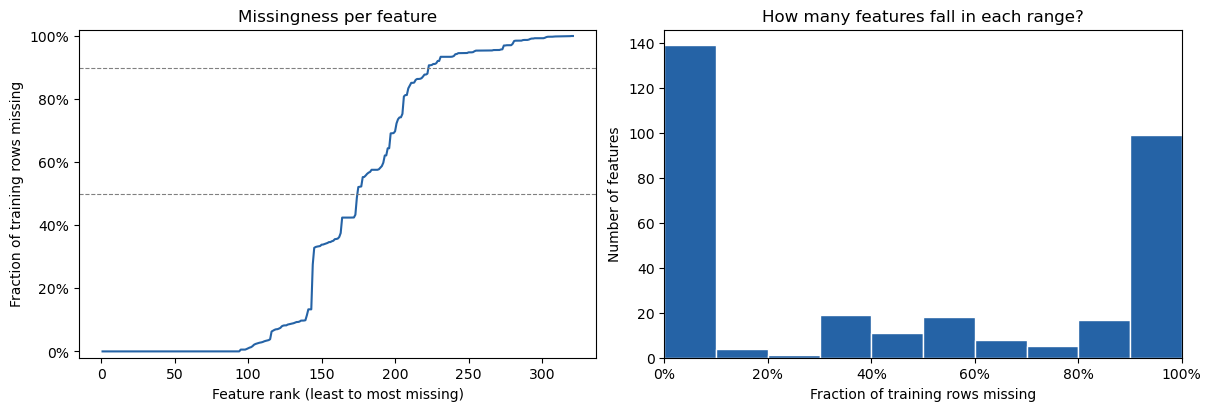

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(np.arange(1, X.shape[1] + 1), np.sort(missing_fraction), color="#2563a6")
for threshold in (0.50, 0.90):
    axes[0].axhline(threshold, color="gray", linestyle="--", linewidth=0.8)
axes[0].set(xlabel="Feature rank (least to most missing)", ylabel="Fraction of training rows missing", title="Missingness per feature", ylim=(-0.02, 1.02))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].hist(missing_fraction, bins=np.linspace(0, 1, 11), color="#2563a6", edgecolor="white")
axes[1].set(xlabel="Fraction of training rows missing", ylabel="Number of features", title="How many features fall in each range?", xlim=(0, 1))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
plt.show()

### How many entries are missing for a typical example?

Column-level and row-level missingness answer different questions. A mostly missing column concerns one feature; a mostly missing row concerns one person’s available information.

A **percentile** locates a value in an ordered distribution. For example, the median (50th percentile) splits the examples into a lower and an upper half. The numbers below refer to raw missing cells, not necessarily unavailable information after decoding the survey.

  0th percentile:   86.0 missing features out of 321 (26.8%)
 25th percentile:  132.0 missing features out of 321 (41.1%)
 50th percentile:  139.0 missing features out of 321 (43.3%)
 75th percentile:  152.0 missing features out of 321 (47.4%)
 90th percentile:  166.0 missing features out of 321 (51.7%)
100th percentile:  218.0 missing features out of 321 (67.9%)


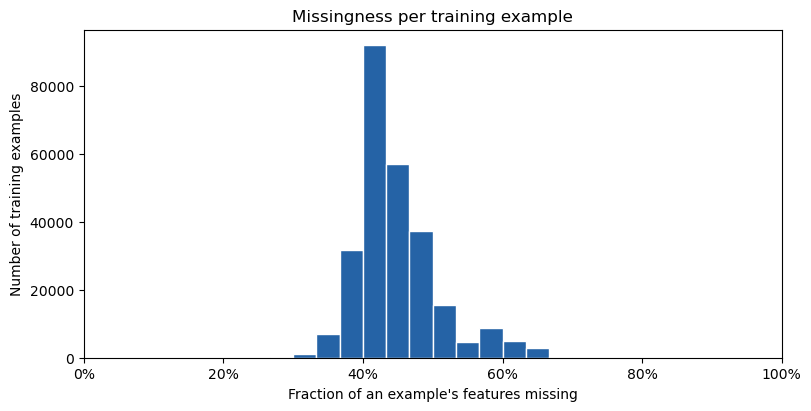

In [9]:
for percentile in (0, 25, 50, 75, 90, 100):
    count = np.percentile(missing_per_row, percentile)
    print(f"{percentile:>3}th percentile: {count:6.1f} missing features out of {X.shape[1]} ({count / X.shape[1]:.1%})")

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.hist(row_missing_fraction, bins=np.linspace(0, 1, 31), color="#2563a6", edgecolor="white")
ax.set(xlabel="Fraction of an example's features missing", ylabel="Number of training examples", title="Missingness per training example", xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.show()

## 5. Findings and what they do not yet imply

The following summary is calculated from this run rather than copied from earlier exploration. No columns have been removed and no values have been imputed (filled in).

In [10]:
print(f"We reserved {len(val_idx):,} validation examples and retained {len(train_idx):,} for training exploration.")
print(f"The positive share in the training portion is {np.mean(y[train_idx] == 1):.2%}.")
print(f"Raw NaNs occupy {missing_fraction.mean():.2%} of training feature cells.")
print(f"{np.count_nonzero(missing_fraction > 0.90)} of {X.shape[1]} features are more than 90% missing.")
print(f"The median training example has {np.median(missing_per_row):.0f} missing features.")

We reserved 65,627 validation examples and retained 262,508 for training exploration.
The positive share in the training portion is 8.83%.
Raw NaNs occupy 44.78% of training feature cells.
99 of 321 features are more than 90% missing.
The median training example has 139 missing features.


**Interpretation boundaries**

- An entirely missing training column contains no observed training values from which to learn a value effect. Record it as a candidate for removal; no removal is performed here.
- A mostly missing column can still contain useful information. We have not measured its predictive value.
- Columns without NaNs can still contain coded nonresponses. “No NaNs” is not the same as “fully usable.”
- These plots do not identify survey skip rules or prove why values are missing. That requires the questionnaire/codebook.
- The per-feature plots do not establish whether the same people are missing the same survey sections. That is a separate question about joint missingness.

**Next step below:** work through one feature, `GENHLTH`, using the official codebook. We will inspect its training distribution and positive-label rates, then demonstrate an encoding. No model is fitted in this notebook yet.

## 6. Understand one feature: `GENHLTH`

**Question:** what do the numbers in this column actually mean, and what representation would make sense for our model?

We start with this feature because it is easy to interpret and illustrates ordered categories plus special answer codes. We have not established that it is the best predictor. We use the same `train_idx` as above; validation features and labels are not used in this section.

### 6.1 Verify meaning against the source

Source: [CDC 2015 BRFSS codebook, page 13, Health Status, variable GENHLTH](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf#page=13). The [2015 documentation page](https://www.cdc.gov/brfss/annual_data/annual_2015.html) provides the original reference materials.

| Stored value | Meaning |
|---|---|
| 1 | Excellent |
| 2 | Very good |
| 3 | Good |
| 4 | Fair |
| 5 | Poor |
| 7 | Unknown / not sure |
| 9 | Refused |
| Blank (`NaN` in our array) | Not asked or missing |

`GENHLTH` is the respondent's assessment of their general health. It is a raw survey answer, not a measurement in physical units. The codebook's published counts describe its full survey file; they need not equal our training counts.

**Interpretation:** 1–5 are ordered categories, but their spacing is not established. Codes 7 and 9 are not health ratings. A blank alone does not identify why an answer is absent. This feature may reflect an existing condition, so an association with the label should not be interpreted as a prediction of future disease.

In [11]:
# Keep source facts separate from our later modeling choices.
GENHLTH_SPEC = {
    "name": "GENHLTH",
    "meaning": "Self-rated general health",
    "type": "ordered categorical",
    "valid_codes": (1, 2, 3, 4, 5),
    "nonresponse_codes": (7, 9),
    "labels": {
        1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor",
        7: "Unknown / not sure", 9: "Refused",
    },
    "source": "https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf#page=13",
}

matches = np.flatnonzero(feature_names == GENHLTH_SPEC["name"])
assert len(matches) == 1
j_genhlth = int(matches[0])
genhlth_raw = X[train_idx, j_genhlth].copy()
y_training = y[train_idx]
allowed_codes = np.array(GENHLTH_SPEC["valid_codes"] + GENHLTH_SPEC["nonresponse_codes"])
unexpected = np.unique(genhlth_raw[~np.isnan(genhlth_raw) & ~np.isin(genhlth_raw, allowed_codes)])
assert unexpected.size == 0, f"Undocumented GENHLTH values: {unexpected}"
print("Observed numeric codes:", np.unique(genhlth_raw[~np.isnan(genhlth_raw)]))
print("Codebook check passed: every observed value has a documented interpretation.")

Observed numeric codes: [1. 2. 3. 4. 5. 7. 9.]
Codebook check passed: every observed value has a documented interpretation.


### 6.2 Count every answer, including nonresponses

Each row below corresponds to one documented answer or to `NaN`. The percentage denominator is **all training examples**, so the rows sum to 100%.

We distinguish raw missing cells from coded nonresponses. A column can have almost no `NaN` values and still contain answers that do not provide a health rating. We keep 7, 9, and `NaN` separate while exploring, even if we later choose to combine them for a baseline model.

In [12]:
genhlth_codes = [1, 2, 3, 4, 5, 7, 9, np.nan]
genhlth_labels = [GENHLTH_SPEC["labels"][c] for c in genhlth_codes[:-1]] + ["Blank / NaN"]
genhlth_masks = [np.isnan(genhlth_raw) if np.isnan(c) else genhlth_raw == c for c in genhlth_codes]
genhlth_counts = np.array([np.count_nonzero(mask) for mask in genhlth_masks])
assert genhlth_counts.sum() == len(train_idx)

print(f"{'Code':<7} {'Meaning':<23} {'Examples':>10} {'Share of training':>19}")
for c, label, count in zip(genhlth_codes, genhlth_labels, genhlth_counts):
    code_text = "NaN" if np.isnan(c) else str(int(c))
    print(f"{code_text:<7} {label:<23} {count:>10,} {count / len(train_idx):>18.3%}")

raw_missing = np.isnan(genhlth_raw)
coded_nonresponse = np.isin(genhlth_raw, GENHLTH_SPEC["nonresponse_codes"])
no_health_rating = raw_missing | coded_nonresponse
print(f"\nRaw NaN cells: {raw_missing.sum():,} ({raw_missing.mean():.3%})")
print(f"Coded nonresponses: {coded_nonresponse.sum():,} ({coded_nonresponse.mean():.3%})")
print(f"No usable health rating: {no_health_rating.sum():,} ({no_health_rating.mean():.3%})")

Code    Meaning                   Examples   Share of training
1       Excellent                   45,515            17.339%
2       Very good                   86,465            32.938%
3       Good                        81,389            31.004%
4       Fair                        34,893            13.292%
5       Poor                        13,529             5.154%
7       Unknown / not sure             466             0.178%
9       Refused                        250             0.095%
NaN     Blank / NaN                      1             0.000%

Raw NaN cells: 1 (0.000%)
Coded nonresponses: 716 (0.273%)
No usable health rating: 717 (0.273%)


### 6.3 Plot how common each answer is

Bar length measures the number of training examples, not disease frequency. Nonresponses are gray and remain visible as labeled rows even when their bars are very small or zero.

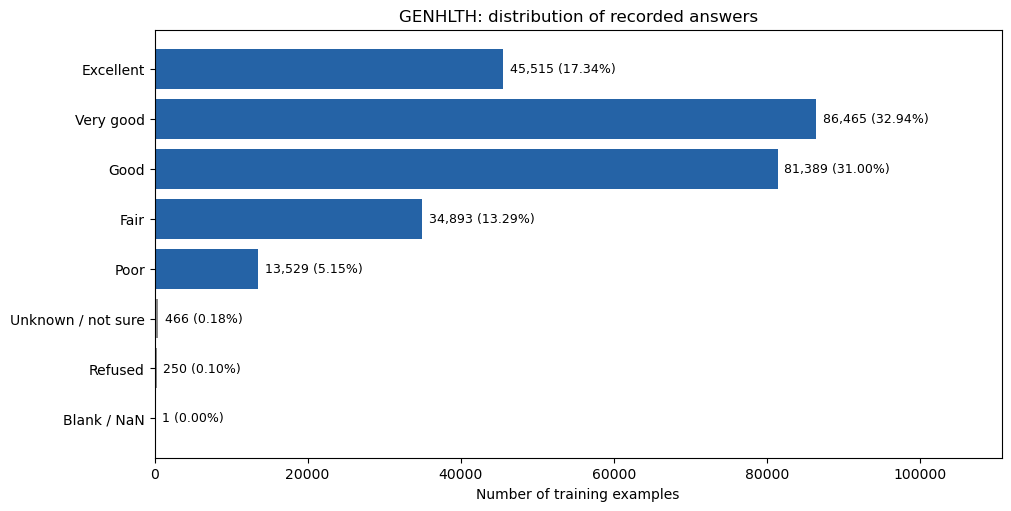

In [13]:
genhlth_colors = ["#2563a6"] * 5 + ["#8a8a8a"] * 3
positions = np.arange(len(genhlth_labels))
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
bars = ax.barh(positions, genhlth_counts, color=genhlth_colors)
ax.set_yticks(positions, genhlth_labels)
ax.invert_yaxis()
ax.set(xlabel="Number of training examples", title="GENHLTH: distribution of recorded answers")
ax.set_xlim(0, genhlth_counts.max() * 1.28)
for bar, count in zip(bars, genhlth_counts):
    ax.annotate(f"{count:,} ({count / len(train_idx):.2%})",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
plt.show()

### 6.4 Compare positive-label rates across answers

For one category, the **positive-label rate** is:

$$\frac{\text{examples with label +1 in this category}}{\text{all examples in this category}}.$$

The denominator is now the category's size, not the full training set. A rate of 20% means 20 positive labels per 100 examples in that group. `y_training == 1` produces a boolean array: summing it counts positive labels.

We show group sizes and positive counts alongside rates. An empty category has an **undefined** rate (`n/a`), not 0%. Small groups provide less stable descriptive rates. These are unweighted summaries of our training records, not survey-weighted estimates for the US population.

Answer                    Examples   Positive labels   Positive rate
Excellent                   45,515               949           2.09%
Very good                   86,465             3,706           4.29%
Good                        81,389             7,372           9.06%
Fair                        34,893             6,668          19.11%
Poor                        13,529             4,374          32.33%
Unknown / not sure             466                76          16.31%
Refused                        250                35          14.00%
Blank / NaN                      1                 0           0.00%

Overall training positive-label rate: 8.83%


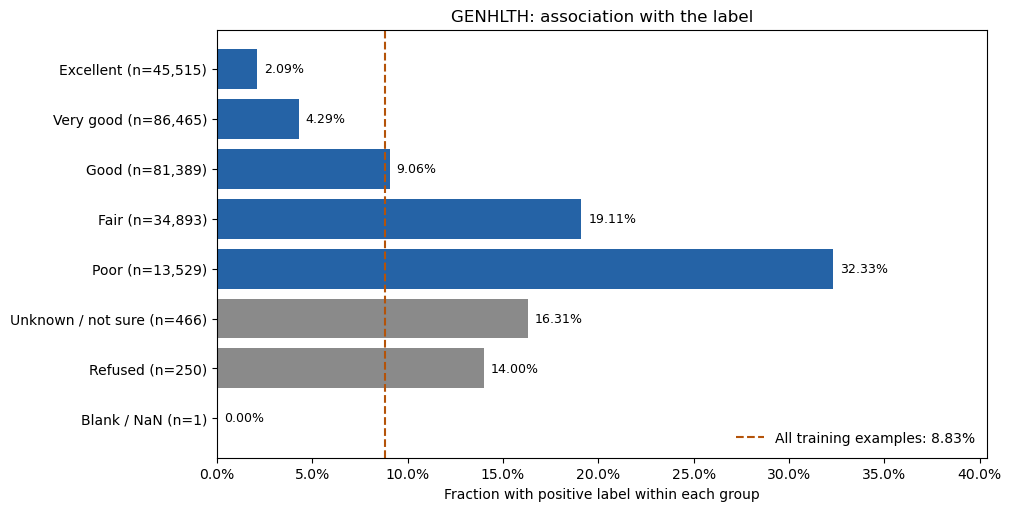

In [14]:
genhlth_positive_counts = np.array([np.count_nonzero(y_training[mask] == 1) for mask in genhlth_masks])
genhlth_positive_rates = np.divide(
    genhlth_positive_counts, genhlth_counts,
    out=np.full(len(genhlth_counts), np.nan, dtype=float),
    where=genhlth_counts > 0,
)
overall_positive_rate = np.mean(y_training == 1)
assert genhlth_positive_counts.sum() == np.count_nonzero(y_training == 1)

print(f"{'Answer':<23} {'Examples':>10} {'Positive labels':>17} {'Positive rate':>15}")
for label, count, positives, rate in zip(genhlth_labels, genhlth_counts, genhlth_positive_counts, genhlth_positive_rates):
    rate_text = "n/a" if np.isnan(rate) else f"{rate:.2%}"
    print(f"{label:<23} {count:>10,} {positives:>17,} {rate_text:>15}")
print(f"\nOverall training positive-label rate: {overall_positive_rate:.2%}")

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
nonempty = genhlth_counts > 0
ax.barh(positions[nonempty], genhlth_positive_rates[nonempty], color=np.array(genhlth_colors)[nonempty])
ax.set_yticks(positions, [f"{label} (n={count:,})" for label, count in zip(genhlth_labels, genhlth_counts)])
ax.invert_yaxis()
ax.axvline(overall_positive_rate, color="#b45309", linestyle="--", label=f"All training examples: {overall_positive_rate:.2%}")
ax.set(xlabel="Fraction with positive label within each group", title="GENHLTH: association with the label")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, min(1.15, max(0.10, np.nanmax(genhlth_positive_rates)) * 1.25))
for position, rate in zip(positions, genhlth_positive_rates):
    ax.annotate("n/a" if np.isnan(rate) else f"{rate:.2%}",
                (0 if np.isnan(rate) else rate, position),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
ax.legend(loc="lower right", frameon=False)
plt.show()

### 6.5 What does this tell us?

The next cell summarizes the observed relationship without fitting a model. Comparisons use groups within the same training portion.

A difference in rates suggests that the feature is worth evaluating as a predictor. It does **not** establish causation, future disease risk, or predictive performance on validation data. Other characteristics, such as age, can differ between these groups. Existing illness can also influence how people rate their general health.

The frequency plot and the positive-rate plot answer different questions: a large category need not have a high positive rate, and a high-rate category need not contain many people.

Read the `n` labels before interpreting a bar: a displayed 0% for a group with one example means that single example has a negative label. It is not reliable evidence that the underlying positive rate is zero.

In [15]:
excellent_rate = genhlth_positive_rates[0]
poor_rate = genhlth_positive_rates[4]
if np.isfinite(excellent_rate) and np.isfinite(poor_rate):
    print(f"Excellent: {excellent_rate:.2%} positive; Poor: {poor_rate:.2%} positive.")
    print(f"Difference (Poor minus Excellent): {(poor_rate - excellent_rate) * 100:.2f} percentage points.")
print(f"The five health-rating groups contain {(~no_health_rating).sum():,} training examples.")
print(f"The {no_health_rating.sum():,} remaining examples have no health rating; they are not worse-than-poor ratings.")

Excellent: 2.09% positive; Poor: 32.33% positive.
Difference (Poor minus Excellent): 30.25 percentage points.
The five health-rating groups contain 261,791 training examples.
The 717 remaining examples have no health rating; they are not worse-than-poor ratings.


### 6.6 Propose an encoding, then inspect it

**Modeling choice for a first baseline:** retain the five ratings as separate categories, and combine 7, 9, and `NaN` into a sixth category, **No rating**. Pooling is our choice, not a codebook rule; it loses distinctions between nonresponse reasons, so we can compare alternatives later.

With **one-hot encoding**, each category receives its own 0/1 column. A row has 1 in its category and 0 elsewhere. This lets a linear or logistic model learn a separate contribution for each group without assuming equal spacing or treating 7 and 9 as health scores. It also does not force the fitted effects to follow the category order.

If a model also has an **intercept** (a constant starting score, represented by a column of ones), using all six indicator columns creates exact redundancy: they sum to the intercept column. We therefore demonstrate five indicator columns with **Excellent as the reference category**. Its row is all zeros; the intercept represents its starting score. The other categories have an indicator that changes that score. This is a proposed model representation, not a replacement for the raw data.

The function does not use labels or estimate any statistics. Its documented mapping can therefore be applied unchanged to future validation/test rows. We do not apply it to those rows here.

In [16]:
def encode_genhlth(values):
    """Five indicator columns, with Excellent as reference; 7/9/NaN become No rating."""
    values = np.asarray(values, dtype=float)
    assert values.ndim == 1
    known = np.isin(values, [1, 2, 3, 4, 5, 7, 9]) | np.isnan(values)
    if not np.all(known):
        raise ValueError(f"Undocumented GENHLTH values: {np.unique(values[~known])}")
    no_rating = np.isin(values, [7, 9]) | np.isnan(values)
    encoded = np.column_stack([
        values == 2, values == 3, values == 4, values == 5, no_rating,
    ]).astype(float)
    return encoded

genhlth_encoded_names = ["Very good", "Good", "Fair", "Poor", "No rating"]
genhlth_encoded_train = encode_genhlth(genhlth_raw)
assert genhlth_encoded_train.shape == (len(train_idx), 5)
assert np.isfinite(genhlth_encoded_train).all()
assert np.array_equal(genhlth_encoded_train.sum(axis=1), (genhlth_raw != 1).astype(float))
assert np.array_equal(X[train_idx, j_genhlth], genhlth_raw, equal_nan=True)

# These are illustrative values, not actual selected people's records.
demo_values = np.array([1, 2, 3, 4, 5, 7, 9, np.nan])
demo_encoded = encode_genhlth(demo_values)
print(f"{'Raw':>6}", " ".join(f"{name:>10}" for name in genhlth_encoded_names))
for value, encoded in zip(demo_values, demo_encoded):
    label = "NaN" if np.isnan(value) else str(int(value))
    print(f"{label:>6}", " ".join(f"{int(v):>10}" for v in encoded))
print("\nTraining encoding shape:", genhlth_encoded_train.shape)
print("No intercept has been added yet. Raw X is unchanged; no model has been fitted.")

   Raw  Very good       Good       Fair       Poor  No rating
     1          0          0          0          0          0
     2          1          0          0          0          0
     3          0          1          0          0          0
     4          0          0          1          0          0
     5          0          0          0          1          0
     7          0          0          0          0          1
     9          0          0          0          0          1
   NaN          0          0          0          0          1

Training encoding shape: (262508, 5)
No intercept has been added yet. Raw X is unchanged; no model has been fitted.


### 6.7 Decision record and next feature

| Question | Current decision or finding |
|---|---|
| What does the feature represent? | Self-rated general health; meanings linked to the 2015 codebook above. |
| What validation did we perform? | Every observed training code was checked against the documented set; counts account for every training row. |
| What did we explore? | Answer frequencies and positive-label rates, including nonresponses. |
| What representation do we propose? | Five category indicators, with Excellent as reference and nonresponses pooled as No rating; add an intercept when building a model. |
| What is still unproven? | Whether this representation improves held-out performance or is preferable to alternatives. |
| Did we alter raw data or examine validation features? | No. |

Below, repeat the process for **`PHYSHLTH`**, which illustrates a different issue: a special code can represent a valid quantity rather than a missing answer. We will verify that mapping before transforming it. For each additional feature, keep the same sequence: **document meaning → check observed values → describe distributions → examine label associations → propose an encoding**.

## 7. Explore the remaining four features

Here “features” means input columns; the **label** remains the known target `y`. Every positive-label rate below is calculated from training labels. It is not a model prediction.

We keep the existing split and examine only training rows. For each feature: verify meaning, audit observed values, summarize missingness, examine its distribution and association with the label, and choose a simple representation to evaluate later.

Two small helpers make the repeated tables and plots consistent. Every group includes its count; missing groups remain visible. We require each training example to belong to exactly one group. Plotted bins are descriptive choices, not automatically the representation used by the model.

In [17]:
def training_feature(name):
    """Read one named feature on the existing training rows only."""
    matches = np.flatnonzero(feature_names == name)
    assert len(matches) == 1, f"Expected exactly one column named {name}"
    return X[train_idx, int(matches[0])].copy()


def audit_numeric(name, values):
    """Describe observed numeric values before any replacement of missing entries."""
    observed = values[np.isfinite(values)]
    assert observed.size > 0, f"No observed values for {name}"
    assert not np.isinf(values).any()
    print(f"{name}: {len(values):,} rows; {np.isnan(values).sum():,} NaNs ({np.isnan(values).mean():.2%})")
    for q, value in zip([0, 25, 50, 75, 99, 100], np.percentile(observed, [0, 25, 50, 75, 99, 100])):
        print(f"  {q:>3}th percentile: {value:.2f}")


def summarize_groups(title, labels, masks, nonresponse_groups=()):
    """Print counts/rates and plot disjoint groups covering every training row."""
    masks = np.asarray(masks, dtype=bool)
    assert masks.shape == (len(labels), len(y_training))
    assert np.all(masks.sum(axis=0) == 1), "Groups must be exhaustive and nonoverlapping."
    counts = masks.sum(axis=1)
    positives = np.array([np.count_nonzero(y_training[m] == 1) for m in masks])
    rates = np.divide(positives, counts, out=np.full(len(labels), np.nan), where=counts > 0)
    assert positives.sum() == np.count_nonzero(y_training == 1)
    print(title)
    print(f"{'Group':<28} {'Examples':>10} {'Share':>10} {'Positive':>10} {'Rate':>10}")
    for label, n, k, rate in zip(labels, counts, positives, rates):
        rate_text = 'n/a' if np.isnan(rate) else f'{rate:.2%}'
        print(f"{label:<28} {n:>10,} {n / len(y_training):>9.2%} {k:>10,} {rate_text:>10}")
    positions = np.arange(len(labels))
    colors = np.array(['#8a8a8a' if i in nonresponse_groups else '#2563a6' for i in positions])
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(labels) * 0.48)), constrained_layout=True)
    axes[0].barh(positions, counts, color=colors)
    axes[0].set_yticks(positions, labels)
    axes[0].set(xlabel='Training examples', title='How common is each group?', xlim=(0, counts.max() * 1.27))
    for i, n in enumerate(counts):
        axes[0].annotate(f'{n:,}', (n, i), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
    present = counts > 0
    axes[1].barh(positions[present], rates[present], color=colors[present])
    axes[1].set_yticks(positions, [f'n={n:,}' for n in counts])
    axes[1].set(xlabel='Known positive labels / examples in group', title='Positive-label rate', xlim=(0, max(0.12, np.nanmax(rates) * 1.25)))
    axes[1].axvline(np.mean(y_training == 1), color='#b45309', linestyle='--', label=f'Overall: {np.mean(y_training == 1):.2%}')
    axes[1].xaxis.set_major_formatter(PercentFormatter(1))
    axes[1].legend(loc='lower right', frameon=False, fontsize=9)
    for i, rate in enumerate(rates):
        axes[1].annotate('n/a' if np.isnan(rate) else f'{rate:.2%}', (0 if np.isnan(rate) else rate, i), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
    for ax in axes:
        # Preserve space for empty groups even when no rate bar was drawn.
        ax.set_ylim(len(labels) - 0.5, -0.5)
    fig.suptitle(title)
    plt.show()
    return {'labels': list(labels), 'counts': counts, 'positives': positives, 'rates': rates}


def plot_numeric_distribution(title, values, bins, xlabel):
    """Plot every observed value; report how many missing values are excluded."""
    observed = values[np.isfinite(values)]
    hist_counts, _ = np.histogram(observed, bins=bins)
    assert hist_counts.sum() == len(observed), 'Histogram range would omit observed values.'
    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    ax.hist(observed, bins=bins, color='#2563a6', edgecolor='white')
    ax.set(xlabel=xlabel, ylabel='Training examples', title=title)
    plt.show()
    print(f'Histogram includes {len(observed):,} observed values; excludes {np.isnan(values).sum():,} missing values.')

## 8. `PHYSHLTH`: poor-physical-health days

The [codebook, page 13](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf#page=13) defines a count of days during the preceding 30 days:

| Raw value | Meaning / decoding |
|---|---|
| 1–30 | Reported number of days |
| 88 | None: convert to **0 days** |
| 77 | Unknown: no usable day count |
| 99 | Refused: no usable day count |
| Blank | Unavailable; exact reason not established |

This is a **count**, not a category code like `GENHLTH`. Treating 88 as missing would lose valid zero-day answers. Treating it as 88 days would contradict the question's time window. We check every observed code before decoding.

Raw code counts:
  1.0:   10,939
  2.0:   14,589
  3.0:    8,509
  4.0:    4,512
  5.0:    7,369
  6.0:    1,322
  7.0:    4,661
  8.0:      833
  9.0:      212
 10.0:    5,342
 11.0:       50
 12.0:      573
 13.0:       68
 14.0:    2,673
 15.0:    4,966
 16.0:      112
 17.0:       96
 18.0:      144
 19.0:       28
 20.0:    3,215
 21.0:      676
 22.0:       73
 23.0:       56
 24.0:       79
 25.0:    1,264
 26.0:       77
 27.0:      100
 28.0:      526
 29.0:      237
 30.0:   20,115
 77.0:    4,488
 88.0:  163,374
 99.0:    1,229
  nan:        1

Converted 163,374 occurrences of 88 to zero days.
Decoded PHYSHLTH (days): 262,508 rows; 5,718 NaNs (2.18%)
    0th percentile: 0.00
   25th percentile: 0.00
   50th percentile: 0.00
   75th percentile: 3.00
   99th percentile: 30.00
  100th percentile: 30.00


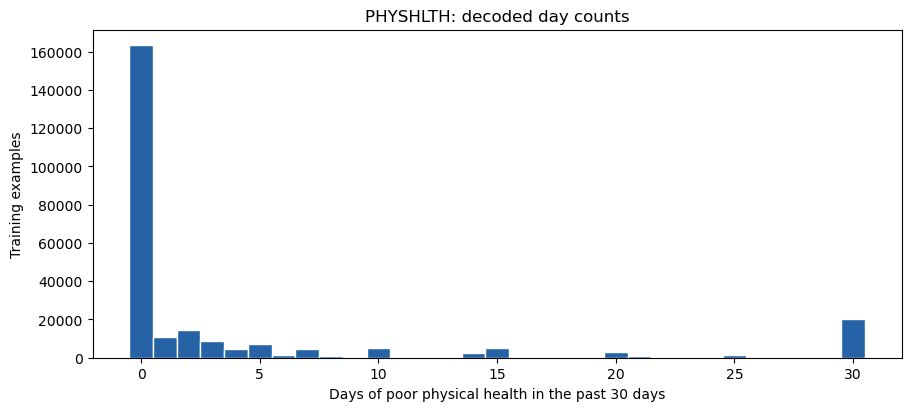

Histogram includes 256,790 observed values; excludes 5,718 missing values.


In [18]:
phys_raw = training_feature('PHYSHLTH')
phys_allowed = np.r_[np.arange(1, 31), [77, 88, 99]]
phys_unexpected = np.unique(phys_raw[~np.isnan(phys_raw) & ~np.isin(phys_raw, phys_allowed)])
assert phys_unexpected.size == 0, f'Unexpected PHYSHLTH codes: {phys_unexpected}'
phys_days = phys_raw.copy()
phys_days[phys_raw == 88] = 0
phys_days[np.isin(phys_raw, [77, 99])] = np.nan
assert np.all(np.isnan(phys_days) | ((phys_days >= 0) & (phys_days <= 30)))
print('Raw code counts:')
for value, count in zip(*np.unique(phys_raw, return_counts=True)):
    print(f'{value:>5}: {count:>8,}')
print(f'\nConverted {np.count_nonzero(phys_raw == 88):,} occurrences of 88 to zero days.')
audit_numeric('Decoded PHYSHLTH (days)', phys_days)
plot_numeric_distribution('PHYSHLTH: decoded day counts', phys_days, np.arange(-0.5, 31.5, 1), 'Days of poor physical health in the past 30 days')

PHYSHLTH: day counts and known labels
Group                          Examples      Share   Positive       Rate
0 days                          163,374    62.24%      9,644      5.90%
1–7 days                         51,901    19.77%      4,295      8.28%
8–14 days                         9,751     3.71%      1,382     14.17%
15–29 days                       11,649     4.44%      2,262     19.42%
30 days                          20,115     7.66%      4,676     23.25%
Unknown (77)                      4,488     1.71%        729     16.24%
Refused (99)                      1,229     0.47%        192     15.62%
Blank / NaN                           1     0.00%          0      0.00%


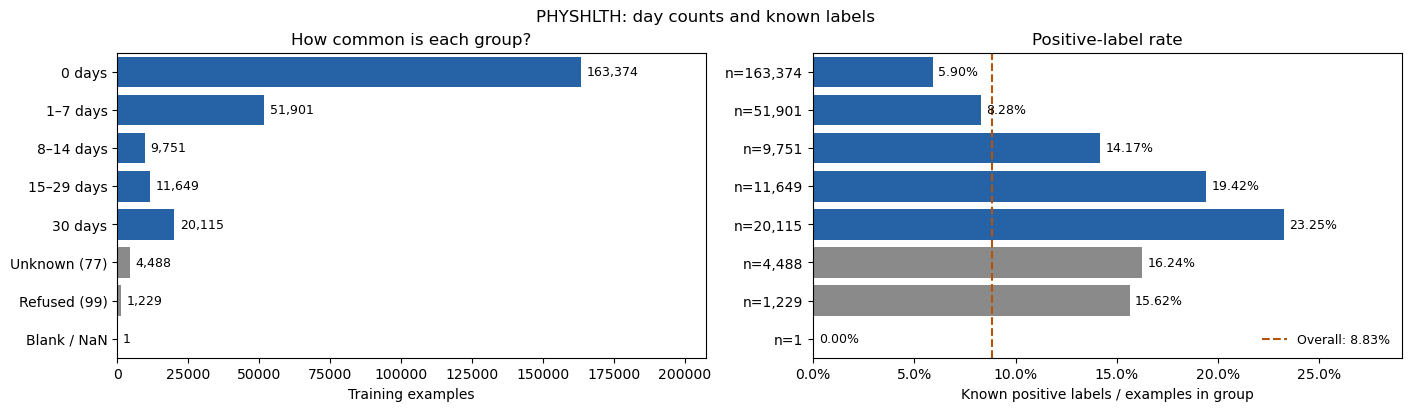

Zero-day positive rate: 5.90%; 30-day rate: 23.25%.


In [19]:
# Prespecified descriptive ranges; nonresponse reasons remain separate here.
phys_labels = ['0 days', '1–7 days', '8–14 days', '15–29 days', '30 days', 'Unknown (77)', 'Refused (99)', 'Blank / NaN']
phys_masks = [phys_days == 0, (phys_days >= 1) & (phys_days <= 7),
              (phys_days >= 8) & (phys_days <= 14), (phys_days >= 15) & (phys_days <= 29),
              phys_days == 30, phys_raw == 77, phys_raw == 99, np.isnan(phys_raw)]
phys_summary = summarize_groups('PHYSHLTH: day counts and known labels', phys_labels, phys_masks, nonresponse_groups=(5, 6, 7))
print(f"Zero-day positive rate: {phys_summary['rates'][0]:.2%}; 30-day rate: {phys_summary['rates'][4]:.2%}.")

**Interpretation and baseline choice:** the spike at zero is a real response pattern. A spike at 30 represents respondents reporting poor physical health throughout the time window; it is not automatically an outlier to remove. Rates summarize associations with existing labels, not a causal effect of the number of days.

For the first baseline, use the numeric day count. Replace unknown values with the training median and add a 0/1 **missing indicator** recording whether replacement was needed. The indicator distinguishes an imputed zero from an actual reported zero when the median is zero. This is a simple starting representation; category ranges or nonlinear effects can be compared later.

## 9. `_SMOKER3`: smoking status

Sources: [codebook, page 117](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf#page=117) and [calculated-variable definitions, page 24](https://www.cdc.gov/brfss/annual_data/2015/pdf/2015_Calculated_Variables_Version4_08_10_17-508c.pdf#page=24).

| Code | Meaning |
|---|---|
| 1 | Currently smokes daily |
| 2 | Currently smokes on some days |
| 3 | Former smoker |
| 4 | Non-smoker category |
| 9 | Unknown / refused / missing |

The survey's classification uses a lifetime threshold of 100 cigarettes: code 4 means below that threshold, not necessarily literally zero cigarettes ever. Codes 1–3 meet the threshold and differ in current smoking status.

These codes do not form a meaningful equally spaced measurement. We will inspect 9 and any `NaN` separately, then propose categorical indicators.

Observed codes: [1. 2. 3. 4. 9.]
Raw NaNs: 0; code 9: 10,546
_SMOKER3: smoking groups and known labels
Group                          Examples      Share   Positive       Rate
Current: daily                   26,021     9.91%      2,691     10.34%
Current: some days               10,564     4.02%      1,054      9.98%
Former                           72,765    27.72%      9,801     13.47%
Non-smoker (<100 lifetime)      142,612    54.33%      8,809      6.18%
Unknown / missing (9)            10,546     4.02%        825      7.82%
Blank / NaN                           0     0.00%          0        n/a


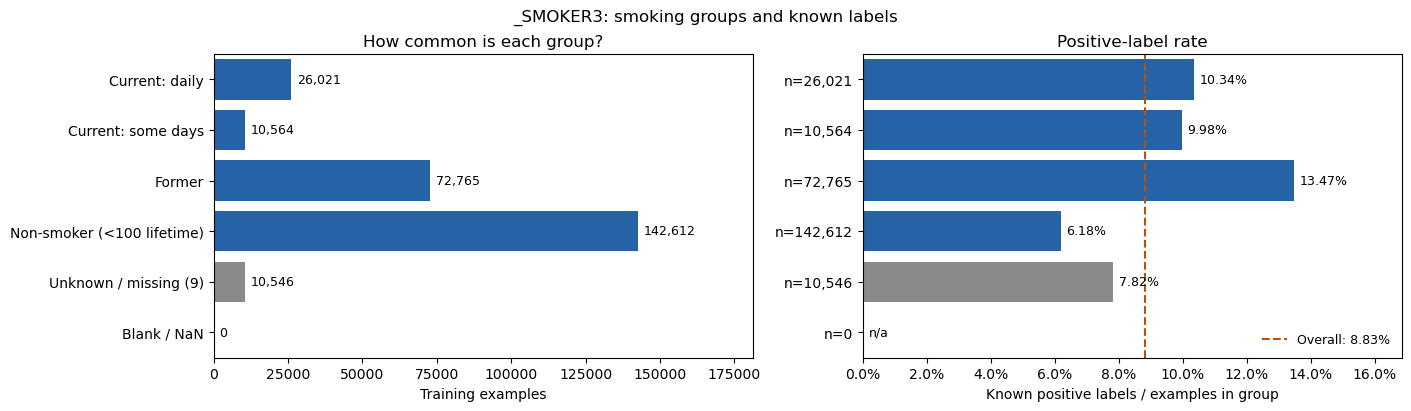

Former-smoker rate: 13.47%; current daily rate: 10.34%.


In [20]:
smoking_raw = training_feature('_SMOKER3')
smoking_unexpected = np.unique(smoking_raw[~np.isnan(smoking_raw) & ~np.isin(smoking_raw, [1, 2, 3, 4, 9])])
assert smoking_unexpected.size == 0, f'Unexpected smoking codes: {smoking_unexpected}'
print('Observed codes:', np.unique(smoking_raw))
print(f'Raw NaNs: {np.isnan(smoking_raw).sum():,}; code 9: {np.count_nonzero(smoking_raw == 9):,}')
smoking_labels = ['Current: daily', 'Current: some days', 'Former', 'Non-smoker (<100 lifetime)', 'Unknown / missing (9)', 'Blank / NaN']
smoking_masks = [smoking_raw == c for c in [1, 2, 3, 4, 9]] + [np.isnan(smoking_raw)]
smoking_summary = summarize_groups('_SMOKER3: smoking groups and known labels', smoking_labels, smoking_masks, nonresponse_groups=(4, 5))
print(f"Former-smoker rate: {smoking_summary['rates'][2]:.2%}; current daily rate: {smoking_summary['rates'][0]:.2%}.")

**Interpretation and baseline choice:** a higher observed rate among former smokers would not show that quitting increases disease risk. These groups can differ in age, exposure history, and whether an existing illness preceded quitting. The plot does not isolate these factors.

Use five categories: daily, some days, former, non-smoker, and unknown. Pool code 9 and `NaN` into unknown for this first baseline. With an intercept, retain four indicator columns and use the non-smoker category as the reference. No artificial numeric ordering is imposed.

## 10. `_BMI5`: verify units before transforming

Sources: [codebook, page 115](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf#page=115) and [calculation documentation, pages 21–22](https://www.cdc.gov/brfss/annual_data/2015/pdf/2015_Calculated_Variables_Version4_08_10_17-508c.pdf#page=21).

BMI is derived from weight divided by squared height, in kg/m². The source file specification stores it with two implied decimal places. However, **our course CSV already contains decimal BMI values**, such as 26.91. We verify the observed range and consistency with `_BMI5CAT` below; we must **not divide this column by 100 again**.

The source calculation leaves BMI unavailable for several reasons, including unavailable inputs, pregnancy, or values outside its accepted range. A blank does not identify which reason applied. We validate observed CSV values against 12 ≤ BMI < 100. This is a source-processing check, not a statement that every value in that range is clinically typical.

We use `_BMI5CAT` only as an independent representation check, not as another predictor. Fixed ranges in the association plot are descriptive; the baseline will initially use numeric BMI.

BMI as stored in this CSV (kg/m²): 262,508 rows; 21,674 NaNs (8.26%)
    0th percentile: 12.02
   25th percentile: 23.73
   50th percentile: 26.91
   75th percentile: 30.90
   99th percentile: 49.48
  100th percentile: 97.65
First five observed training values: [41.98 21.52 33.47 30.67 35.94]
BMI-category consistency: 240,834 comparable rows, 0 mismatches.
BMI/category missing-status disagreements: 0
No rescaling applied: this CSV already stores BMI in kg/m².


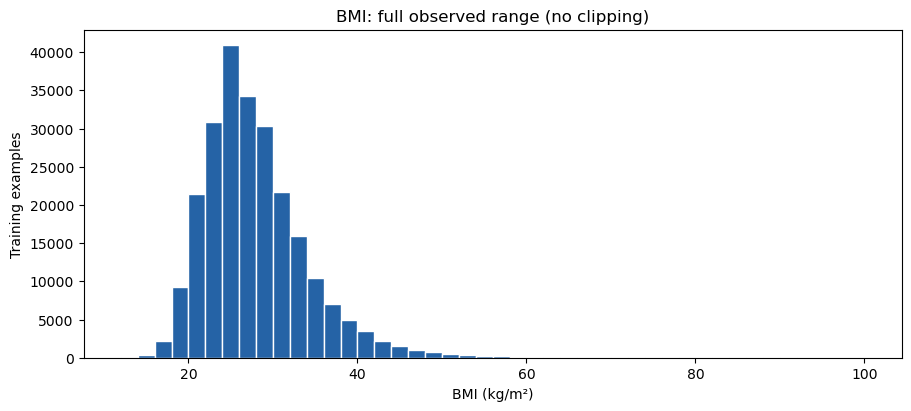

Histogram includes 240,834 observed values; excludes 21,674 missing values.


In [21]:
bmi = training_feature('_BMI5')
bmi_observed = ~np.isnan(bmi)
assert np.all((bmi[bmi_observed] >= 12) & (bmi[bmi_observed] < 100)), 'Unexpected BMI scale/range: investigate before conversion.'
audit_numeric('BMI as stored in this CSV (kg/m²)', bmi)
print('First five observed training values:', bmi[bmi_observed][:5])

bmi_category = training_feature('_BMI5CAT')
expected_bmi_category = np.full(len(bmi), np.nan)
expected_bmi_category[bmi_observed] = np.select(
    [bmi[bmi_observed] < 18.5, bmi[bmi_observed] < 25, bmi[bmi_observed] < 30],
    [1, 2, 3], default=4,
)
category_comparable = bmi_observed & ~np.isnan(bmi_category)
assert np.count_nonzero(category_comparable) > 0
category_mismatches = np.count_nonzero(bmi_category[category_comparable] != expected_bmi_category[category_comparable])
assert category_mismatches == 0, 'BMI values disagree with their supplied categories.'
print(f'BMI-category consistency: {category_comparable.sum():,} comparable rows, {category_mismatches} mismatches.')
print('BMI/category missing-status disagreements:', np.count_nonzero(np.isnan(bmi) != np.isnan(bmi_category)))
print('No rescaling applied: this CSV already stores BMI in kg/m².')
plot_numeric_distribution('BMI: full observed range (no clipping)', bmi, np.linspace(12, 100, 45), 'BMI (kg/m²)')

BMI: descriptive ranges and known labels
Group                          Examples      Share   Positive       Rate
12–<18.5                          4,076     1.55%        356      8.73%
18.5–<25                         78,346    29.85%      5,291      6.75%
25–<30                           87,387    33.29%      8,060      9.22%
30–<35                           43,461    16.56%      4,817     11.08%
35–<40                           16,480     6.28%      1,964     11.92%
40–<100                          11,084     4.22%      1,368     12.34%
Missing                          21,674     8.26%      1,324      6.11%


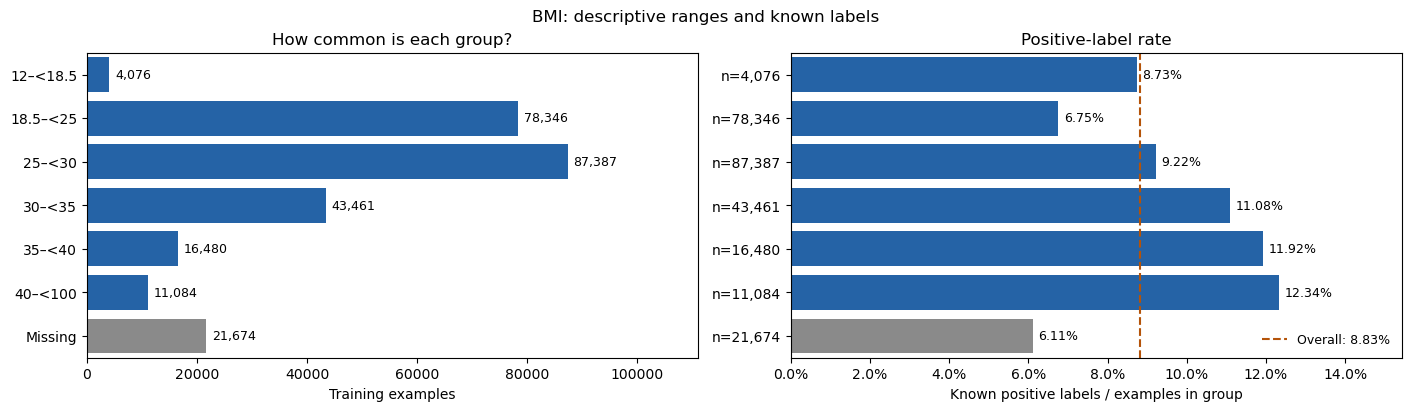

Observed BMI median: 26.91; missing: 8.26%.


In [22]:
bmi_labels = ['12–<18.5', '18.5–<25', '25–<30', '30–<35', '35–<40', '40–<100', 'Missing']
bmi_edges = [12, 18.5, 25, 30, 35, 40, 100]
bmi_masks = [(bmi >= left) & (bmi < right) for left, right in zip(bmi_edges[:-1], bmi_edges[1:])] + [np.isnan(bmi)]
bmi_summary = summarize_groups('BMI: descriptive ranges and known labels', bmi_labels, bmi_masks, nonresponse_groups=(6,))
print(f"Observed BMI median: {np.nanmedian(bmi):.2f}; missing: {np.isnan(bmi).mean():.2%}.")

**Interpretation and baseline choice:** the long tail is visible rather than silently removed. Values that look unusual deserve investigation; neither their rarity nor this plot alone proves an error. The grouped positive rates can vary nonlinearly and can reflect other differences between people.

Keep the verified numeric BMI values, fill missing values with the training median, and add a missing indicator. We will scale the numeric values for gradient descent. No clipping or outlier deletion is performed. A single numeric coefficient is an intentionally simple baseline; bins or nonlinear terms can be tested later.

## 11. `_AGE80`: imputation and an upper cap

The [calculation documentation, page 19](https://www.cdc.gov/brfss/annual_data/2015/pdf/2015_Calculated_Variables_Version4_08_10_17-508c.pdf#page=19) defines `_AGE80` using imputed age: ages 18–79 remain numeric, while ages 80 and above are stored as 80.

**Imputation** means the data provider has already filled unavailable age values. This column alone does not identify which entries were originally reported versus filled in. **Capping** means we cannot distinguish an 80-year-old from someone older using this feature.

Check that observed entries are whole numbers in 18–80. Interpret a spike at 80 as an accumulated 80+ group, not evidence that all those people are exactly 80.

_AGE80 (years; 80 means 80+): 262,508 rows; 0 NaNs (0.00%)
    0th percentile: 18.00
   25th percentile: 43.00
   50th percentile: 58.00
   75th percentile: 69.00
   99th percentile: 80.00
  100th percentile: 80.00
Rows recorded as 80+: 21,684 (8.26%)


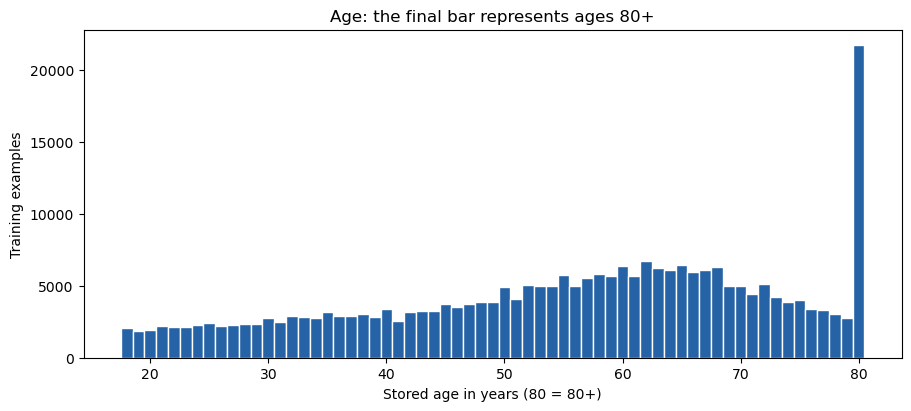

Histogram includes 262,508 observed values; excludes 0 missing values.


In [23]:
age = training_feature('_AGE80')
age_observed = ~np.isnan(age)
assert np.all((age[age_observed] >= 18) & (age[age_observed] <= 80))
assert np.all(age[age_observed] == np.floor(age[age_observed]))
audit_numeric('_AGE80 (years; 80 means 80+)', age)
print(f'Rows recorded as 80+: {np.count_nonzero(age == 80):,} ({np.mean(age == 80):.2%})')
plot_numeric_distribution('Age: the final bar represents ages 80+', age, np.arange(17.5, 81.5, 1), 'Stored age in years (80 = 80+)')

Age: ranges and known labels
Group                          Examples      Share   Positive       Rate
18–29                            26,183     9.97%        180      0.69%
30–39                            28,550    10.88%        364      1.27%
40–49                            34,261    13.05%      1,052      3.07%
50–59                            51,875    19.76%      3,330      6.42%
60–69                            60,745    23.14%      6,723     11.07%
70–79                            39,210    14.94%      6,705     17.10%
80+                              21,684     8.26%      4,826     22.26%
Missing                               0     0.00%          0        n/a


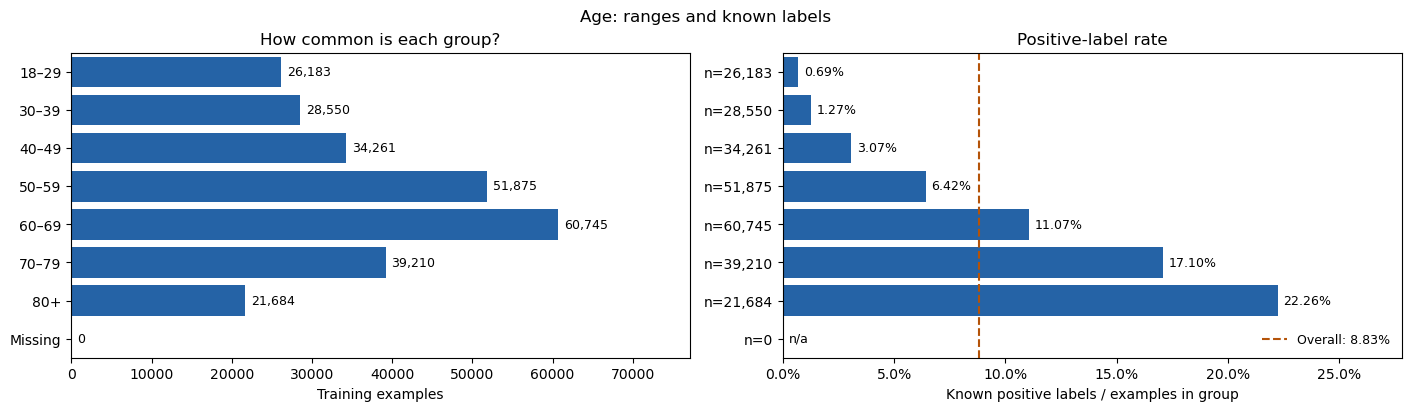

18–29 positive rate: 0.69%; 80+ rate: 22.26%.


In [24]:
age_labels = ['18–29', '30–39', '40–49', '50–59', '60–69', '70–79', '80+', 'Missing']
age_edges = [18, 30, 40, 50, 60, 70, 80]
age_masks = [(age >= left) & (age < right) for left, right in zip(age_edges[:-1], age_edges[1:])] + [age == 80, np.isnan(age)]
age_summary = summarize_groups('Age: ranges and known labels', age_labels, age_masks, nonresponse_groups=(7,))
print(f"18–29 positive rate: {age_summary['rates'][0]:.2%}; 80+ rate: {age_summary['rates'][6]:.2%}.")

**Interpretation and baseline choice:** retain the capped numeric value and scale it using training statistics. We cannot recover exact ages above 80 or reconstruct the original missing-age indicator from this column. The simple baseline uses one numeric age coefficient; age bins or nonlinear terms are later experiments.

As with the other features, this is an unadjusted association in our training sample. It is not a causal estimate or a prediction of future events.

## 12. Prepare a small baseline input matrix

We now have five understood input features. Preparing them does not train a classifier. **No model predictions or validation scores are produced in this section.**

| Input | First-baseline representation |
|---|---|
| `GENHLTH` | Five indicators; Excellent is reference; nonresponses pooled |
| `PHYSHLTH` | Decoded numeric days + missing indicator |
| `_SMOKER3` | Four indicators; non-smoker is reference; nonresponses pooled |
| `_BMI5` | Numeric BMI in the CSV's existing units + missing indicator |
| `_AGE80` | Numeric capped age |

We add an intercept column of ones. The number of model columns differs from the number of original features because categories become multiple columns.

For numeric columns:
1. Calculate the median using observed **training** values, then fill missing entries.
2. Calculate the filled training column's mean μ and standard deviation σ.
3. Transform values as `(value − μ) / σ`, so numeric features have comparable scales. This helps gradient descent avoid steps dominated by a feature's units.
4. Retain a missing indicator only where its value varies in training. An all-zero indicator has no effect to learn.

The medians, means, standard deviations, category mappings, and column order must be reused unchanged on validation/test examples. **Do not recompute them on those examples.** The functions below separate learning preprocessing statistics (`fit`) from applying them (`transform`). Numeric features are scaled; 0/1 category indicators stay 0/1. All raw arrays remain unchanged.

In [25]:
BASELINE_FEATURES = ['GENHLTH', 'PHYSHLTH', '_SMOKER3', '_BMI5', '_AGE80']
NUMERIC_NAMES = ['PHYSHLTH_days', 'BMI', 'AGE80']
CATEGORICAL_NAMES = ['GENHLTH_very_good', 'GENHLTH_good', 'GENHLTH_fair', 'GENHLTH_poor', 'GENHLTH_no_rating',
                     'SMOKER_daily', 'SMOKER_some_days', 'SMOKER_former', 'SMOKER_unknown']
baseline_columns = [int(np.flatnonzero(feature_names == name)[0]) for name in BASELINE_FEATURES]
raw_baseline_train = X[np.ix_(train_idx, baseline_columns)]


def decode_baseline_features(raw):
    """Validate/decode our five CSV features without fitting statistics or changing raw."""
    raw = np.asarray(raw, dtype=float)
    if raw.ndim != 2 or raw.shape[1] != len(BASELINE_FEATURES):
        raise ValueError('Expected a matrix with columns in BASELINE_FEATURES order.')
    health, physical, smoking, bmi_values, age_values = raw.T
    health_indicators = encode_genhlth(health)
    if not np.all(np.isnan(physical) | np.isin(physical, np.r_[np.arange(1, 31), [77, 88, 99]])):
        raise ValueError('Unexpected PHYSHLTH code.')
    days = np.where(physical == 88, 0, physical)
    days = np.where(np.isin(physical, [77, 99]), np.nan, days)
    if not np.all(np.isnan(smoking) | np.isin(smoking, [1, 2, 3, 4, 9])):
        raise ValueError('Unexpected _SMOKER3 code.')
    smoking_indicators = np.column_stack([smoking == 1, smoking == 2, smoking == 3,
                                          (smoking == 9) | np.isnan(smoking)]).astype(float)
    if not np.all(np.isnan(bmi_values) | ((bmi_values >= 12) & (bmi_values < 100))):
        raise ValueError('Unexpected BMI scale/range; expected CSV values in kg/m².')
    if not np.all(np.isnan(age_values) | ((age_values >= 18) & (age_values <= 80) & (age_values == np.floor(age_values)))):
        raise ValueError('Unexpected _AGE80 value.')
    categories = np.column_stack([health_indicators, smoking_indicators])
    numeric = np.column_stack([days, bmi_values, age_values])
    return categories, numeric


def fit_baseline_preprocessor(raw_training):
    """Estimate replacements and scaling on training examples only."""
    _, numeric = decode_baseline_features(raw_training)
    missing = np.isnan(numeric)
    if np.any(missing.all(axis=0)):
        raise ValueError('A numeric feature has no observed training values.')
    medians = np.nanmedian(numeric, axis=0)
    filled = np.where(missing, medians, numeric)
    means = filled.mean(axis=0)
    scales = filled.std(axis=0)
    scales = np.where(scales == 0, 1.0, scales)
    keep_missing = missing.any(axis=0) & ~missing.all(axis=0)
    return {'medians': medians, 'means': means, 'scales': scales, 'keep_missing': keep_missing}


def transform_baseline_features(raw, state):
    """Apply fixed training preprocessing; do not refit on the supplied rows."""
    categories, numeric = decode_baseline_features(raw)
    missing = np.isnan(numeric)
    filled = np.where(missing, state['medians'], numeric)
    standardized = (filled - state['means']) / state['scales']
    matrix = np.column_stack([np.ones(len(raw)), categories, standardized,
                              missing[:, state['keep_missing']].astype(float)])
    if not np.isfinite(matrix).all():
        raise ValueError('Prepared matrix contains nonfinite entries.')
    return matrix


baseline_preprocessor = fit_baseline_preprocessor(raw_baseline_train)
baseline_train_matrix = transform_baseline_features(raw_baseline_train, baseline_preprocessor)
baseline_column_names = ['intercept'] + CATEGORICAL_NAMES + [name + '_scaled' for name in NUMERIC_NAMES] + [
    name + '_missing' for name, keep in zip(NUMERIC_NAMES, baseline_preprocessor['keep_missing']) if keep]
y_baseline_train = (y_training == 1).astype(float)

assert baseline_train_matrix.shape == (len(train_idx), len(baseline_column_names))
assert np.all(baseline_train_matrix[:, 0] == 1)
assert np.array_equal(raw_baseline_train, X[np.ix_(train_idx, baseline_columns)], equal_nan=True)
assert np.allclose(baseline_train_matrix[:, 10:13].mean(axis=0), 0, atol=1e-10)
assert np.allclose(baseline_train_matrix[:, 10:13].std(axis=0), 1, atol=1e-10)
print('Training model matrix:', baseline_train_matrix.shape)
print('Columns:', ', '.join(baseline_column_names))
print('Logistic target labels:', np.unique(y_baseline_train))
print(f"{'Numeric feature':<18} {'Median fill':>12} {'Mean after fill':>17} {'Std after fill':>16} {'Missing flag':>14}")
for j, name in enumerate(NUMERIC_NAMES):
    print(f"{name:<18} {baseline_preprocessor['medians'][j]:>12.3f} {baseline_preprocessor['means'][j]:>17.3f} {baseline_preprocessor['scales'][j]:>16.3f} {str(baseline_preprocessor['keep_missing'][j]):>14}")
print('Raw data preserved; all model inputs finite. Validation/test features were not transformed or analyzed.')

Training model matrix: (262508, 15)
Columns: intercept, GENHLTH_very_good, GENHLTH_good, GENHLTH_fair, GENHLTH_poor, GENHLTH_no_rating, SMOKER_daily, SMOKER_some_days, SMOKER_former, SMOKER_unknown, PHYSHLTH_days_scaled, BMI_scaled, AGE80_scaled, PHYSHLTH_days_missing, BMI_missing
Logistic target labels: [0. 1.]
Numeric feature     Median fill   Mean after fill   Std after fill   Missing flag
PHYSHLTH_days             0.000             4.169            8.706           True
BMI                      26.910            27.934            6.395           True
AGE80                    58.000            55.342           17.037          False
Raw data preserved; all model inputs finite. Validation/test features were not transformed or analyzed.


### Inspect a few hypothetical rows

These are invented examples to verify the transformation, not real people's records. They include genuine zero-day answers, coded nonresponses, and blanks. A filled-in day count can equal zero while its missing indicator is 1; a reported zero has indicator 0. Both cases therefore remain distinguishable.

The target conversion above changes course labels from {−1, +1} to {0, 1}, which our logistic-regression implementation requires. This conversion changes the coding, not the known outcome. No probabilities have been predicted yet.

In [26]:
example_raw = np.array([
    [1, 88, 4, 26.91, 58],
    [5, 30, 1, 32.00, 80],
    [7, 77, 9, np.nan, 40],
    [np.nan, np.nan, np.nan, np.nan, np.nan],
], dtype=float)
example_before = example_raw.copy()
example_matrix = transform_baseline_features(example_raw, baseline_preprocessor)
assert np.array_equal(example_raw, example_before, equal_nan=True)
assert example_matrix.shape[1] == baseline_train_matrix.shape[1]
assert np.isfinite(example_matrix).all()
phy_flag = baseline_column_names.index('PHYSHLTH_days_missing')
assert example_matrix[0, phy_flag] == 0 and example_matrix[2, phy_flag] == 1
print('Invented raw rows in order:', BASELINE_FEATURES)
print(example_raw)
print('\nTransformed rows in the model column order printed above:')
with np.printoptions(precision=3, suppress=True):
    print(example_matrix)
print('\nIf a numeric feature had no missing training entries, future missing entries still use its training median, but no missing-effect coefficient was learnable.')

Invented raw rows in order: ['GENHLTH', 'PHYSHLTH', '_SMOKER3', '_BMI5', '_AGE80']
[[ 1.   88.    4.   26.91 58.  ]
 [ 5.   30.    1.   32.   80.  ]
 [ 7.   77.    9.     nan 40.  ]
 [  nan   nan   nan   nan   nan]]

Transformed rows in the model column order printed above:
[[ 1.     0.     0.     0.     0.     0.     0.     0.     0.     0.
  -0.479 -0.16   0.156  0.     0.   ]
 [ 1.     0.     0.     0.     1.     0.     1.     0.     0.     0.
   2.967  0.636  1.447  0.     0.   ]
 [ 1.     0.     0.     0.     0.     1.     0.     0.     0.     1.
  -0.479 -0.16  -0.901  1.     1.   ]
 [ 1.     0.     0.     0.     0.     1.     0.     0.     0.     1.
  -0.479 -0.16   0.156  1.     1.   ]]

If a numeric feature had no missing training entries, future missing entries still use its training median, but no missing-effect coefficient was learnable.


## 13. Ready for the first baseline

The notebook now verifies and describes all five selected features, documents preprocessing choices, and produces `baseline_train_matrix`, `y_baseline_train`, and `baseline_preprocessor` in memory. Rerunning the notebook reconstructs them from the CSVs and seed 42; no separate cache or prediction file is written.

**What we can conclude:** the features have understandable mappings and observed associations worth evaluating. Counts and rates in these plots are descriptive training statistics, not predictions, causal effects, or held-out performance. Numeric histograms retain their full observed ranges. No rows were discarded for missing selected features.

**Next baseline experiment:** compare always predicting the majority class with logistic regression using this matrix. Apply the already fitted preprocessing to validation rows, train on the training portion, then examine a confusion matrix (counts of correct and incorrect positive/negative predictions), precision, recall, and F1 as well as accuracy. Use an initial probability cutoff of 0.5; any subsequent tuning is a separate experiment. We should verify the competition scoring metric before choosing our primary optimization target.

The one-coefficient-per-numeric-feature assumption is deliberately simple. Nonlinear terms, alternative missingness handling, class weighting, and more features are later comparisons. The baseline gives us a measured starting point against which to evaluate those changes.